In [1]:
import json

train_files = json.load(open("./data/train.json")) 
test_files = json.load(open("./data/test.json"))
val_files = json.load(open("./data/test.json"))


In [2]:
from transformers import AutoTokenizer
model_checkpoint = 'google-bert/bert-base-multilingual-cased'
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)


/home/lfc/.myenv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
#genearte narrative2id from dataset
narrative2id = {}
for split in [train_files, test_files, val_files]:
    for doc in split:
        narrative = doc["dom_narr"]
        if narrative not in narrative2id:
            narrative2id[narrative] = len(narrative2id)
            
narrative2id

{'CC: Amplifying Climate Fears': 0,
 'CC: Climate change is beneficial': 1,
 'CC: Controversy about green technologies': 2,
 'CC: Criticism of climate movement': 3,
 'CC: Criticism of climate policies': 4,
 'CC: Criticism of institutions and authorities': 5,
 'CC: Downplaying climate change': 6,
 'CC: Green policies are geopolitical instruments': 7,
 'CC: Hidden plots by secret schemes of powerful groups': 8,
 'CC: Questioning the measurements and science': 9,
 'URW: Amplifying war-related fears': 10,
 'URW: Blaming the war on others rather than the invader': 11,
 'URW: Discrediting Ukraine': 12,
 'URW: Discrediting the West, Diplomacy': 13,
 'URW: Distrust towards Media': 14,
 'URW: Hidden plots by secret schemes of powerful groups': 15,
 'URW: Negative Consequences for the West': 16,
 'URW: Overpraising the West': 17,
 'URW: Praise of Russia': 18,
 'URW: Russia is the Victim': 19,
 'URW: Speculating war outcomes': 20}

In [4]:
len(narrative2id)

21

In [5]:
def cas_to_dataset_stride(cas, label2id, narrative2id, doc_id, max_length=512, stride=128):
    text = cas["text"]
    entities = [(ent["begin"], ent["end"]) for ent in cas["evidence"]]
    entities = sorted(entities, key=lambda x: x[0])
    narrative = cas["dom_narr"]
    language = cas["language"]
    
    #one hot narrative labels
    #narrative_labels = [0] * len(narrative2id)
    #narrative_labels[narrative2id[narrative]] = 1
    narrative_labels = narrative2id[narrative]

    # truncation="only_second" keeps narrative whole and strides only text,
    # so chunk offsets remain valid against original entity begin/end positions
    encoding = tokenizer(
        #narrative,
        text,
        max_length=max_length,
        stride=stride,
        truncation=True,
        padding="max_length",
        return_offsets_mapping=True,
        return_overflowing_tokens=True
    )

    dataset = []

    for chunk_idx in range(len(encoding["input_ids"])):
        offsets        = encoding["offset_mapping"][chunk_idx]
        input_ids      = encoding["input_ids"][chunk_idx]
        attention_mask = encoding["attention_mask"][chunk_idx]
        sequence_ids   = encoding.sequence_ids(chunk_idx)  # None=special, 0=narrative, 1=text

        # Assign BIO labels only to text tokens (sequence_id == 1)
        labels = ["O"] * len(input_ids)
        for start, end in entities:
            for i, (tok_start, tok_end) in enumerate(offsets):
                if sequence_ids[i] != 0:
                    continue
                if tok_start >= end or tok_end <= start:
                    continue
                if tok_start == start:
                    labels[i] = "B-Evidence"
                else:
                    labels[i] = "I-Evidence"

        # Convert to ids — mask non-text tokens AND subwords with -100
        label_ids = []
        for i, label in enumerate(labels):
            token = tokenizer.convert_ids_to_tokens(int(input_ids[i]))
            if sequence_ids[i] != 0:
                label_ids.append(-100)
                continue
            if token.startswith("##"):
                label_ids.append(-100)
            else:
                label_ids.append(label2id[label])
                
        # BIO fix-up: only inspect non-masked tokens
        fixed_label_ids = []
        prev_valid_label = None
        id2label = {v: k for k, v in label2id.items()}

        for lid in label_ids:
            if lid == -100:
                fixed_label_ids.append(-100)
                # Do NOT update prev_valid_label — subwords are transparent
                continue

            label_name = id2label[lid]

            if label_name.startswith("I-"):
                entity_type = label_name[2:]
                if prev_valid_label is None or not prev_valid_label.endswith(entity_type):
                    label_name = "B-" + entity_type
                    lid = label2id[label_name]

            fixed_label_ids.append(lid)
            prev_valid_label = label_name  # only update on real (non-subword) tokens


        dataset.append({
            "doc_id": doc_id,
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "labels": fixed_label_ids,
            "narrative_labels": narrative_labels,
            "offset_mapping": offsets,
            "language": language
        })

    return dataset


In [6]:
from datasets import Dataset

#label2id = {'O': 0, 'B-Claim': 1, 'I-Claim': 2, 'B-Claim object': 3, 'I-Claim object': 4,
# 'B-Claim span': 5, 'I-Claim span': 6, 'B-Claimer': 7, 'I-Claimer': 8,
# 'B-Non-claim': 9, 'I-Non-claim': 10, 'B-Time': 11, 'I-Time': 12}

label2id = {'O': 0, 'B-Evidence': 1, 'I-Evidence': 2}

id2label = {i: label for i, label in enumerate(label2id.keys())}

def generateDataset(files):
    data_list = []
    for file in files:
        #if file["doc_id"] == "EN_UA_300129.txt":
            data_list = data_list + cas_to_dataset_stride(file, label2id, narrative2id, file["doc_id"])
    return Dataset.from_list(data_list)


from sklearn.model_selection import train_test_split
from datasets import Dataset, DatasetDict

# 1️⃣ Split your CAS files
#train_files, test_files = files[:672], files[672:]

#filtered_train_files, filtered_file_names = filter_files(train_files, file_names[:672])

train_dataset = generateDataset(train_files)
test_dataset = generateDataset(test_files)
val_dataset = generateDataset(val_files)
#print(len(train_dataset), len(test_dataset))
#data_list_test = generateDatasets(files_test)

#['QSLINK', 'TLINK', 'SRLINK']
#{'QSLINK': 0, 'TLINK': 1, 'SRLINK': 2}
train_dataset

Dataset({
    features: ['doc_id', 'input_ids', 'attention_mask', 'labels', 'narrative_labels', 'offset_mapping', 'language'],
    num_rows: 1742
})

In [7]:
len(train_dataset[0]["input_ids"]), len(train_dataset[0]["labels"])

(512, 512)

In [8]:
#count claims and non-claims in the training set
dataset_labels = [id2label[label] for example in train_dataset for label in example["labels"] if label != -100]
from collections import Counter
Counter(dataset_labels)

Counter({'O': 389581, 'I-Evidence': 109512, 'B-Evidence': 4209})

In [9]:
# print toekns and labels for the first example
tokens = tokenizer.convert_ids_to_tokens(train_dataset[100]["input_ids"])
labels = [
    id2label[label] if label != -100 else -100
    for label in train_dataset[100]["labels"]
]
for token, label in zip(tokens, labels):
    print(f"{token}\t{label}")

[CLS]	-100
##tra	-100
"	B-Evidence
do	I-Evidence
El	I-Evidence
Niño	I-Evidence
-	I-Evidence
Os	I-Evidence
##cil	-100
##ação	-100
do	I-Evidence
Sul	I-Evidence
.	O
Isto	B-Evidence
apo	I-Evidence
##nta	-100
para	I-Evidence
a	I-Evidence
influência	I-Evidence
maior	I-Evidence
do	I-Evidence
que	I-Evidence
nunca	I-Evidence
das	I-Evidence
alter	I-Evidence
##ações	-100
c	I-Evidence
##lim	-100
##áticas	-100
,	I-Evidence
im	I-Evidence
##pulsion	-100
##adas	-100
pela	I-Evidence
quei	I-Evidence
##ma	-100
de	I-Evidence
com	I-Evidence
##bust	-100
##íveis	-100
f	I-Evidence
##ós	-100
##sei	-100
##s	-100
,	I-Evidence
no	I-Evidence
aumento	I-Evidence
das	I-Evidence
temperaturas	I-Evidence
g	I-Evidence
##lob	-100
##ais	-100
.	O
"	O
A	O
passa	O
##da	-100
segunda	O
-	O
feira	O
pode	O
ter	O
esta	O
##bele	-100
##cido	-100
um	B-Evidence
novo	I-Evidence
recorde	I-Evidence
mundial	I-Evidence
da	I-Evidence
temperatura	I-Evidence
média	I-Evidence
global	I-Evidence
absoluta	I-Evidence
mais	I-Evidence
quen	I-Evidenc

In [10]:
from transformers import DataCollatorForTokenClassification

data_collator = DataCollatorForTokenClassification(tokenizer)

In [11]:

batch_size = 16

In [12]:
label2id

{'O': 0, 'B-Evidence': 1, 'I-Evidence': 2}

In [13]:
from torch.utils.data import DataLoader
import torch

def collate_fn(batch):
    return {
        "input_ids": torch.tensor([x["input_ids"] for x in batch]),
        "attention_mask": torch.tensor([x["attention_mask"] for x in batch]),
        "token_labels": torch.tensor([x["labels"] for x in batch]),
        "narrative_labels": torch.tensor([x["narrative_labels"] for x in batch]),
        "offset_mapping": [x["offset_mapping"] for x in batch],
        "doc_id": [x["doc_id"] for x in batch],
        "language": [x["language"] for x in batch]
    }

#add seed to shuffle for reproducibility
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn, generator=torch.Generator().manual_seed(42))
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn, generator=torch.Generator().manual_seed(42))
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=True, collate_fn=collate_fn, generator=torch.Generator().manual_seed(42))

In [14]:
list(train_loader)[-1]

{'input_ids': tensor([[  101,   117, 36897,  ...,     0,     0,     0],
         [  101, 30720, 10104,  ...,     0,     0,     0],
         [  101, 10316, 40703,  ...,     0,     0,     0],
         [  101, 10135, 12364,  ..., 25259, 18283,   102],
         [  101, 11639, 10708,  ...,     0,     0,     0],
         [  101, 57548,   117,  ...,   553, 44011,   102]]),
 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 1, 1, 1],
         [1, 1, 1,  ..., 0, 0, 0],
         [1, 1, 1,  ..., 1, 1, 1]]),
 'token_labels': tensor([[-100,    1,    2,  ..., -100, -100, -100],
         [-100,    0,    0,  ..., -100, -100, -100],
         [-100, -100, -100,  ..., -100, -100, -100],
         [-100,    1,    2,  ...,    0,    0, -100],
         [-100,    0,    0,  ..., -100, -100, -100],
         [-100, -100,    0,  ...,    0, -100, -100]]),
 'narrative_labels': tensor([ 6, 13, 10,  6,  8, 13]),
 'offset_m

In [15]:
import torch
import torch.nn as nn
from transformers import AutoModel


class MultiTaskModel(nn.Module):

    def __init__(self, model_name, num_narratives, num_token_labels):
        super().__init__()

        self.encoder = AutoModel.from_pretrained(model_name)

        hidden_size = self.encoder.config.hidden_size

        self.narrative_classifier = nn.Linear(hidden_size, num_narratives)
        self.token_classifier = nn.Linear(hidden_size, num_token_labels)

        self.dropout = nn.Dropout(0.1)

    def forward(self, input_ids, attention_mask):

        outputs = self.encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        sequence_output = outputs.last_hidden_state

        pooled_output = sequence_output[:, 0]

        pooled_output = self.dropout(pooled_output)
        sequence_output = self.dropout(sequence_output)

        narrative_logits = self.narrative_classifier(pooled_output)
        token_logits = self.token_classifier(sequence_output)

        return {
            "narrative_logits": narrative_logits,
            "token_logits": token_logits
        }

In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = MultiTaskModel(
    model_name="bert-base-multilingual-cased",
    num_narratives=len(narrative2id),
    num_token_labels=len(label2id)
).to(device)

In [17]:
import torch
import torch.nn as nn

narrative_loss_fct = nn.CrossEntropyLoss()
token_loss_fct = nn.CrossEntropyLoss(ignore_index=-100)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)

In [18]:
torch.cuda.is_available()

True

In [19]:
from tqdm import tqdm
import torch
from collections import defaultdict

def train_model(
    model,
    train_loader,
    optimizer,
    token_loss_fct,
    narrative_loss_fct,
    device,
    alpha=0.5,
    beta=1.0
):

    model.train()


    model.train()

    total_loss = 0
    total_token_loss = 0
    total_narr_loss = 0

    loop = tqdm(train_loader, desc="Training")

    for batch in loop:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        token_labels = batch["token_labels"].to(device)
        narrative_labels = batch["narrative_labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # -------------------------
        # TOKEN LOSS (evidence)
        # -------------------------
        token_loss = token_loss_fct(
            outputs["token_logits"].view(-1, outputs["token_logits"].size(-1)),
            token_labels.view(-1)
        )

        # -------------------------
        # NARRATIVE LOSS (doc-level max pooling)
        # -------------------------

        doc_logits = defaultdict(list)
        doc_labels = {}

        for i, doc_id in enumerate(batch["doc_id"]):
            doc_logits[doc_id].append(outputs["narrative_logits"][i])
            doc_labels[doc_id] = narrative_labels[i]

        agg_logits = torch.stack([
            torch.stack(doc_logits[d]).max(dim=0).values
            for d in doc_logits
        ])
        agg_labels = torch.stack([doc_labels[d] for d in doc_logits])

        narrative_loss = narrative_loss_fct(agg_logits, agg_labels)

        # -------------------------
        # COMBINED LOSS
        # -------------------------
        loss = alpha * narrative_loss + beta * token_loss

        loss.backward()
        optimizer.step()

        # -------------------------
        # LOGGING
        # -------------------------
        total_loss += loss.item()
        total_token_loss += token_loss.item()
        total_narr_loss += narrative_loss.item()

        loop.set_postfix({
            "loss": loss.item(),
            "narr": narrative_loss.item(),
            "token": token_loss.item()
        })

    return {
        "loss": total_loss / len(train_loader),
        "token_loss": total_token_loss / len(train_loader),
        "narrative_loss": total_narr_loss / len(train_loader)
    }

In [20]:
from collections import defaultdict
import torch.nn.functional as F


def tokens_to_spans(pred_labels, offset_mapping):
    spans = []
    current_label = None
    start_char = None
    prev_end_char = None

    for (tok_start, tok_end), label in zip(offset_mapping, pred_labels):
        # Skip special tokens or padding
        if tok_start is None or tok_end is None or tok_start == tok_end:
            continue

        # Subword token: extend current span if inside one
        if label == -100:
            if current_label is not None:
                prev_end_char = tok_end
            continue

        if label.startswith("B-"):
            if current_label:
                spans.append((start_char, prev_end_char, current_label))
            current_label = label[2:]
            start_char = tok_start
        elif label.startswith("I-") and current_label == label[2:]:
            prev_end_char = tok_end
        else:  # O or mismatch
            if current_label:
                spans.append((start_char, prev_end_char, current_label))
                current_label = None

        prev_end_char = tok_end

    if current_label:
        spans.append((start_char, prev_end_char, current_label))

    return spans


def merge_stride_predictions_confidence(predictions, label_map):

    doc_tokens = defaultdict(dict)  # doc_id -> {token_start: (best_conf, pred_label, true_label)}
    doc_offsets = defaultdict(list) # doc_id -> list of (start_char, end_char)
    for sample in predictions:
        doc_id = sample["doc_id"]
        offsets = sample["offset_mapping"]
        logits_list = sample["logits"]
        labels = sample["labels"]

        for (start, end), logits, t in zip(offsets, logits_list, labels):
            #if t == -100:
            #    continue  # skip subword/special tokens

            probs = F.softmax(torch.tensor(logits), dim=-1)
            best_conf, best_idx = torch.max(probs, dim=-1)
            pred_label = label_map[int(best_idx)]
            #true_label = label_map[int(t)]

            if t == -100:
                true_label = -100  # keep so subwords can extend span later
            else:
                true_label = label_map[int(t)]

            # if token already seen, keep the most confident prediction
            if start in doc_tokens[doc_id]:
                #if best_conf > doc_tokens[doc_id][start][0]:
                #    doc_tokens[doc_id][start] = (best_conf, pred_label, true_label)
                pass
            else:
                doc_tokens[doc_id][start] = (best_conf, pred_label, true_label)
            
            # keep track of document-level offsets
            if start not in [s for s, e in doc_offsets[doc_id]]:
                doc_offsets[doc_id].append((start, end))

    y_true_per_doc = []
    y_pred_per_doc = []

    for doc_id in doc_tokens:
        token_starts = sorted(doc_tokens[doc_id].keys())
        doc_true_labels = []
        doc_pred_labels = []

        for start in token_starts:
            _, pred_label, true_label = doc_tokens[doc_id][start]
            doc_pred_labels.append(pred_label)
            doc_true_labels.append(true_label)

        y_true_per_doc.append(doc_true_labels)
        y_pred_per_doc.append(doc_pred_labels)

        # sort offsets for the document
        doc_offsets[doc_id] = sorted(doc_offsets[doc_id], key=lambda x: x[0])
    return y_true_per_doc, y_pred_per_doc, doc_offsets


def evaluate_with_tolerance_per_class(y_true_spans, y_pred_spans, tolerance=5):

    stats = defaultdict(lambda: {"tp": 0, "fp": 0, "fn": 0})

    for doc_true, doc_pred in zip(y_true_spans, y_pred_spans):
        matched_gold = set()

        # Count true positives and false positives
        for p_start, p_end, p_label in doc_pred:
            found_match = False
            for i, (g_start, g_end, g_label) in enumerate(doc_true):
                if i in matched_gold:
                    continue
                if g_label == p_label and abs(p_start - g_start) <= tolerance and abs(p_end - g_end) <= tolerance:
                    stats[p_label]["tp"] += 1
                    matched_gold.add(i)
                    found_match = True
                    break
            if not found_match:
                stats[p_label]["fp"] += 1

        # Count false negatives
        for i, (g_start, g_end, g_label) in enumerate(doc_true):
            if i not in matched_gold:
                stats[g_label]["fn"] += 1

    # Compute per-class precision, recall, F1
    results = {}
    total_tp, total_fp, total_fn = 0, 0, 0
    for label, s in stats.items():
        tp, fp, fn = s["tp"], s["fp"], s["fn"]
        precision = tp / (tp + fp) if tp + fp > 0 else 0
        recall = tp / (tp + fn) if tp + fn > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
        results[label] = {"precision": precision, "recall": recall, "f1": f1}
        total_tp += tp
        total_fp += fp
        total_fn += fn

    # Micro-averaged metrics
    micro_precision = total_tp / (total_tp + total_fp) if total_tp + total_fp > 0 else 0
    micro_recall = total_tp / (total_tp + total_fn) if total_tp + total_fn > 0 else 0
    micro_f1 = 2 * micro_precision * micro_recall / (micro_precision + micro_recall) if micro_precision + micro_recall > 0 else 0
    results["micro"] = {"precision": micro_precision, "recall": micro_recall, "f1": micro_f1}

    return results

In [21]:
from sklearn.metrics import precision_recall_fscore_support
import numpy as np

def compute_narrative_metrics(logits, labels):

    preds = logits.argmax(dim=-1).cpu().numpy()
    labels = labels.cpu().long().numpy()

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        preds,
        average="macro",
        zero_division=0
    )

    return precision, recall, f1

In [22]:
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
import torch

def compute_seqeval_metrics(logits, labels, ignore_index=-100):

    preds = logits.argmax(-1).cpu().numpy()
    labels = labels.cpu().numpy()

    true_preds = []
    true_labels = []

    for pred_seq, label_seq in zip(preds, labels):

        pred_tags = []
        label_tags = []

        for p, l in zip(pred_seq, label_seq):

            if l == ignore_index:
                continue

            pred_tags.append(id2label[p])
            label_tags.append(id2label[l])

        true_preds.append(pred_tags)
        true_labels.append(label_tags)

    return {
        "precision": precision_score(true_labels, true_preds),
        "recall": recall_score(true_labels, true_preds),
        "f1": f1_score(true_labels, true_preds)
    }

In [23]:
def compute_iou(p_start, p_end, g_start, g_end):
    """Compute Intersection over Union between two spans."""
    intersection_start = max(p_start, g_start)
    intersection_end = min(p_end, g_end)
    intersection = max(0, intersection_end - intersection_start)
    
    union = (p_end - p_start) + (g_end - g_start) - intersection
    
    if union == 0:
        return 0.0
    return intersection / union


def evaluate_with_iou_per_class(y_true_spans, y_pred_spans, iou_threshold=0):

    stats = defaultdict(lambda: {"tp": 0, "fp": 0, "fn": 0})

    for doc_true, doc_pred in zip(y_true_spans, y_pred_spans):
        matched_gold = set()

        # Count true positives and false positives
        for p_start, p_end, p_label in doc_pred:
            
            # Find best matching gold span (highest IoU)
            best_match = None
            best_iou = 0.0
            for i, (g_start, g_end, g_label) in enumerate(doc_true):
                if i in matched_gold:
                    continue
                if g_label == p_label:
                    iou = compute_iou(p_start, p_end, g_start, g_end)
                    if iou >= iou_threshold and iou > best_iou:
                        best_iou = iou
                        best_match = i

            if best_match is not None:
                stats[p_label]["tp"] += 1
                matched_gold.add(best_match)
            else:
                stats[p_label]["fp"] += 1

        # Count false negatives
        for i, (g_start, g_end, g_label) in enumerate(doc_true):
            if i not in matched_gold:
                stats[g_label]["fn"] += 1

    # Compute per-class precision, recall, F1
    results = {}
    total_tp, total_fp, total_fn = 0, 0, 0
    for label, s in stats.items():
        tp, fp, fn = s["tp"], s["fp"], s["fn"]
        precision = tp / (tp + fp) if tp + fp > 0 else 0
        recall = tp / (tp + fn) if tp + fn > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
        results[label] = {"precision": precision, "recall": recall, "f1": f1}
        total_tp += tp
        total_fp += fp
        total_fn += fn

    # Micro-averaged metrics
    micro_precision = total_tp / (total_tp + total_fp) if total_tp + total_fp > 0 else 0
    micro_recall = total_tp / (total_tp + total_fn) if total_tp + total_fn > 0 else 0
    micro_f1 = 2 * micro_precision * micro_recall / (micro_precision + micro_recall) if micro_precision + micro_recall > 0 else 0
    results["micro"] = {"precision": micro_precision, "recall": micro_recall, "f1": micro_f1}

    return results

import pandas as pd
import numpy as np

def evaluate_all_thresholds(y_true_spans_by_lang, y_pred_spans_by_lang, thresholds=None):
    """
    y_true_spans_by_lang: dict {language: y_true_spans}
    y_pred_spans_by_lang: dict {language: y_pred_spans}
    """
    if thresholds is None:
        thresholds = [0.5,0.6,0.7,0.8,0.9,1]

    rows = []

    for lang in y_true_spans_by_lang:
        y_true = y_true_spans_by_lang[lang]
        y_pred = y_pred_spans_by_lang[lang]

        for threshold in thresholds:
            results = evaluate_with_iou_per_class(y_true, y_pred, iou_threshold=threshold)
            
            row = {"language": lang, "threshold": threshold}
            
            # Per-class F1
            for label, metrics in results.items():
                row[f"f1_{label}"] = round(metrics["f1"], 4)
                row[f"precision_{label}"] = round(metrics["precision"], 4)
                row[f"recall_{label}"] = round(metrics["recall"], 4)
            
            rows.append(row)

    # Overall (all languages combined)
    for threshold in thresholds:
        all_true = [span for lang in y_true_spans_by_lang for span in y_true_spans_by_lang[lang]]
        all_pred = [span for lang in y_pred_spans_by_lang for span in y_pred_spans_by_lang[lang]]
        
        results = evaluate_with_iou_per_class(all_true, all_pred, iou_threshold=threshold)
        
        row = {"language": "overall", "threshold": threshold}
        for label, metrics in results.items():
            row[f"f1_{label}"] = round(metrics["f1"], 4)
            row[f"precision_{label}"] = round(metrics["precision"], 4)
            row[f"recall_{label}"] = round(metrics["recall"], 4)
        
        rows.append(row)

    df = pd.DataFrame(rows)
    df = df.sort_values(["language", "threshold"]).reset_index(drop=True)
    #remove last column
    df = df.iloc[:, :-3]
    
    return df

In [ ]:
def evaluate_model(
    model,
    dataloader,
    token_loss_fct,
    narrative_loss_fct,
    compute_narrative_metrics,
    device,
    alpha=1.0, #narrativas
    beta=0.5, #evidence
    id2label=None
):

    model.eval()

    total_loss = 0

    # stride-aware storage
    predictions = []
    # narrative aggregation per document
    doc_narr_logits = defaultdict(list)
    doc_narr_labels = {}  
    doc_language = {}
    with torch.no_grad():

        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            token_labels = batch["token_labels"].to(device)
            narrative_labels = batch["narrative_labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # -------------------------
            # LOSS
            # -------------------------
            token_loss = token_loss_fct(
                outputs["token_logits"].view(-1, outputs["token_logits"].size(-1)),
                token_labels.view(-1)
            )

            # -------------------------
            # NARRATIVE LOSS (doc-level max pooling, same as training)
            # -------------------------
            narr_logits = outputs["narrative_logits"].cpu()
            narr_labels = narrative_labels.cpu()

            doc_ids = batch["doc_id"]
            languages = batch["language"]

            for i, doc_id in enumerate(doc_ids):
                doc_narr_logits[doc_id].append(narr_logits[i])
                doc_narr_labels[doc_id] = narr_labels[i]
                doc_language[doc_id] = languages[i]

            # compute narrative loss per batch via max pooling
            batch_doc_logits = defaultdict(list)
            batch_doc_labels = {}
            for i, doc_id in enumerate(doc_ids):
                batch_doc_logits[doc_id].append(outputs["narrative_logits"][i])
                batch_doc_labels[doc_id] = narrative_labels[i]

            agg_logits = torch.stack([
                torch.stack(batch_doc_logits[d]).max(dim=0).values
                for d in batch_doc_logits
            ])
            agg_labels = torch.stack([batch_doc_labels[d] for d in batch_doc_logits])

            narrative_loss = narrative_loss_fct(agg_logits, agg_labels)

            loss = alpha * narrative_loss + beta * token_loss
            total_loss += loss.item()

            # -------------------------
            # EXTRACT OUTPUTS
            # -------------------------
            logits = outputs["token_logits"].cpu().numpy()
            labels = token_labels.cpu().numpy()

            narr_logits = outputs["narrative_logits"].cpu()
            narr_labels = narrative_labels.cpu()

            offsets = batch["offset_mapping"]
            doc_ids = batch["doc_id"]

            # -------------------------
            # TOKEN PREDICTIONS
            # -------------------------
            logits = outputs["token_logits"].cpu().numpy()
            labels = token_labels.cpu().numpy()
            offsets = batch["offset_mapping"]

            for i in range(len(doc_ids)):
                predictions.append({
                    "doc_id": doc_ids[i],
                    "offset_mapping": offsets[i],
                    "logits": logits[i],
                    "labels": labels[i]
                })

    # =====================================================
    # NARRATIVE: DOC-LEVEL AGGREGATION
    # =====================================================
    final_narr_logits = []
    final_narr_labels = []
    for doc_id in doc_narr_logits:
        logits = torch.stack(doc_narr_logits[doc_id]).max(dim=0).values
        final_narr_logits.append(logits)
        final_narr_labels.append(doc_narr_labels[doc_id])

    final_narr_logits = torch.stack(final_narr_logits)
    final_narr_labels = torch.stack(final_narr_labels)

    n_p, n_r, n_f1 = compute_narrative_metrics(
        final_narr_logits,
        final_narr_labels
    )


 # =====================================================
    # TOKEN STRIDE MERGING
    # =====================================================
    pred_docs, gold_docs, offsets_docs = merge_stride_predictions_confidence(
        predictions,
        id2label
    )

    # =====================================================
    # SPAN DECODING
    # =====================================================
    pred_span_docs = []
    gold_span_docs = []


    for i, doc_id in enumerate(offsets_docs.keys()):
        pred_spans = tokens_to_spans(pred_docs[i], offsets_docs[doc_id])
        gold_spans = tokens_to_spans(gold_docs[i], offsets_docs[doc_id])
        pred_span_docs.append(pred_spans)
        gold_span_docs.append(gold_spans)
        
    
    
    
    results = evaluate_with_tolerance_per_class(gold_span_docs, pred_span_docs, tolerance=0)
    results["narrative"] = {"precision": n_p, "recall": n_r, "f1": n_f1}
    results["loss"] = total_loss / len(dataloader)
    
    
    # =====================================================
    # PER-LANGUAGE RESULTS
    # =====================================================
    lang_pred_spans = defaultdict(list)
    lang_gold_spans = defaultdict(list)
    lang_narr_logits = defaultdict(list)
    lang_narr_labels = defaultdict(list)

    for i, doc_id in enumerate(offsets_docs.keys()):
        lang = doc_language[doc_id]
        lang_pred_spans[lang].append(pred_span_docs[i])
        lang_gold_spans[lang].append(gold_span_docs[i])
        
    #df_results = evaluate_all_thresholds(lang_gold_spans, lang_pred_spans)  # for side-effect of printing table
    #df_results.to_csv("nunu_multi_head_results_by_language_threshold.csv", index=False)
    #print(df_results.to_string())

    for doc_id in doc_narr_logits:
        lang = doc_language[doc_id]
        logits = torch.stack(doc_narr_logits[doc_id]).max(dim=0).values
        lang_narr_logits[lang].append(logits)
        lang_narr_labels[lang].append(doc_narr_labels[doc_id])

    lang_results = {}
    for lang in lang_pred_spans:
        l_narr_logits = torch.stack(lang_narr_logits[lang])
        l_narr_labels = torch.stack(lang_narr_labels[lang])
        n_p, n_r, n_f1 = compute_narrative_metrics(l_narr_logits, l_narr_labels)

        l_results = evaluate_with_tolerance_per_class(
            lang_gold_spans[lang],
            lang_pred_spans[lang],
            tolerance=0
        )
        l_results["narrative"] = {"precision": n_p, "recall": n_r, "f1": n_f1}
        lang_results[lang] = l_results

    results["by_language"] = lang_results

    return results

In [24]:
best_f1 = 0.0
history = []
epochs = 100
alpha=1.0 #narrativas
beta=1.0 #evidence
for epoch in range(epochs):

    # =====================================================
    # TRAIN
    # =====================================================
    train_stats = train_model(
        model=model,
        train_loader=train_loader,
        optimizer=optimizer,
        token_loss_fct=token_loss_fct,
        narrative_loss_fct=narrative_loss_fct,
        device=device,
        alpha=alpha,
        beta=beta
    )

    # =====================================================
    # EVALUATE
    # =====================================================
    results = evaluate_model(
        model=model,
        dataloader=val_loader,
        token_loss_fct=token_loss_fct,
        narrative_loss_fct=narrative_loss_fct,
        compute_narrative_metrics=compute_narrative_metrics,
        device=device,
        alpha=alpha,
        beta=beta,
        id2label=id2label
    )

    # =====================================================
    # TRACK RESULTS
    # =====================================================
    print(results)
    epoch_result = {
        "epoch": epoch,
        "train_loss": train_stats["loss"],
        "val_loss": results["loss"],
        "narrative_f1": results["narrative"]["f1"],
        "evidence_f1": results["Evidence"]["f1"]
    }

    history.append(epoch_result)

    # =====================================================
    # PRINT SUMMARY
    # =====================================================
    print(f"\n================ Epoch {epoch} ================")
    print(f"Train Loss: {epoch_result['train_loss']:.4f}")
    print(f"Val Loss:   {epoch_result['val_loss']:.4f}")
    print(f"Narr F1:    {epoch_result['narrative_f1']:.4f}")
    print(f"Evidence F1:{epoch_result['evidence_f1']:.4f}")

    # =====================================================
    # SAVE BEST MODEL (based on evidence F1)
    # =====================================================
    if results["Evidence"]["f1"] > best_f1:
        best_f1 = results["Evidence"]["f1"]

        torch.save(
            model.state_dict(),
            "best_multitask_model.pt"
        )

        print("💾 New best model saved!")

print("\nTraining complete.")
print("Best Evidence F1:", best_f1)

Training: 100%|██████████| 218/218 [01:56<00:00,  1.87it/s, loss=2.59, narr=1.93, token=0.662]


{'Evidence': {'precision': 0.0, 'recall': 0, 'f1': 0}, 'micro': {'precision': 0.0, 'recall': 0, 'f1': 0}, 'narrative': {'precision': 0.19697895100069013, 'recall': 0.22803571428571429, 'f1': 0.19805533360406055}, 'loss': 2.2548868040884695}

================ Epoch 0 ================
Train Loss: 2.5173
Val Loss:   2.2549
Narr F1:    0.1981
Evidence F1:0.0000


Training: 100%|██████████| 218/218 [01:58<00:00,  1.85it/s, loss=2.76, narr=2.15, token=0.615]  


{'Evidence': {'precision': 0.0, 'recall': 0, 'f1': 0}, 'micro': {'precision': 0.0, 'recall': 0, 'f1': 0}, 'narrative': {'precision': 0.23837732919254656, 'recall': 0.25398809523809524, 'f1': 0.23209244080145722}, 'loss': 2.0779023362744238}

================ Epoch 1 ================
Train Loss: 1.8959
Val Loss:   2.0779
Narr F1:    0.2321
Evidence F1:0.0000


Training: 100%|██████████| 218/218 [01:58<00:00,  1.84it/s, loss=0.932, narr=0.456, token=0.476]


{'Evidence': {'precision': 0.0, 'recall': 0.0, 'f1': 0}, 'micro': {'precision': 0.0, 'recall': 0.0, 'f1': 0}, 'narrative': {'precision': 0.3268137418137418, 'recall': 0.3280952380952381, 'f1': 0.30100202196312037}, 'loss': 2.2995847386698567}

================ Epoch 2 ================
Train Loss: 1.4307
Val Loss:   2.2996
Narr F1:    0.3010
Evidence F1:0.0000


... (190 outputs left out)

Training: 100%|██████████| 218/218 [01:58<00:00,  1.84it/s, loss=0.00486, narr=0.000476, token=0.00439] 


{'Evidence': {'precision': 0.09850107066381156, 'recall': 0.10926365795724466, 'f1': 0.1036036036036036}, 'micro': {'precision': 0.09850107066381156, 'recall': 0.10926365795724466, 'f1': 0.1036036036036036}, 'narrative': {'precision': 0.36070361011537483, 'recall': 0.35446428571428573, 'f1': 0.3416113019447493}, 'loss': 5.147192508943619}

================ Epoch 98 ================
Train Loss: 0.0099
Val Loss:   5.1472
Narr F1:    0.3416
Evidence F1:0.1036


Training: 100%|██████████| 218/218 [01:58<00:00,  1.83it/s, loss=0.004, narr=0.000748, token=0.00326]   


{'Evidence': {'precision': 0.07922912205567452, 'recall': 0.11280487804878049, 'f1': 0.09308176100628932}, 'micro': {'precision': 0.07922912205567452, 'recall': 0.11280487804878049, 'f1': 0.09308176100628932}, 'narrative': {'precision': 0.3490891053391053, 'recall': 0.3448809523809524, 'f1': 0.3294389835224309}, 'loss': 5.203798186394476}

================ Epoch 99 ================
Train Loss: 0.0092
Val Loss:   5.2038
Narr F1:    0.3294
Evidence F1:0.0931

Training complete.
Best Evidence F1: 0.11559432933478733


In [38]:
# is gpu available?
torch.cuda.is_available()

True

In [44]:
#load best model and evaluate on test set
model.load_state_dict(torch.load("best_multitask_model.pt"))

test_results = evaluate_model(
    model=model,
    dataloader=test_loader,
    token_loss_fct=token_loss_fct,
    narrative_loss_fct=narrative_loss_fct,
    compute_narrative_metrics=compute_narrative_metrics,
    device=device,
    alpha=1,
    beta=1,
    id2label=id2label
)

   language  threshold  f1_Evidence  precision_Evidence  recall_Evidence
0        BG        0.5       0.1250              0.0946           0.1842
1        BG        0.6       0.1250              0.0946           0.1842
2        BG        0.7       0.1250              0.0946           0.1842
3        BG        0.8       0.1071              0.0811           0.1579
4        BG        0.9       0.1071              0.0811           0.1579
5        BG        1.0       0.0714              0.0541           0.1053
6        EN        0.5       0.1637              0.1505           0.1795
7        EN        0.6       0.1287              0.1183           0.1410
8        EN        0.7       0.1170              0.1075           0.1282
9        EN        0.8       0.1053              0.0968           0.1154
10       EN        0.9       0.0936              0.0860           0.1026
11       EN        1.0       0.0351              0.0323           0.0385
12       PT        0.5       0.2888              0.

/home/lfc/.myenv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples.
  type_true = type_of_target(y_true, input_name="y_true")
/home/lfc/.myenv/lib/python3.11/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples.
  ys_types = set(type_of_target(x) for x in ys)
/home/lfc/.myenv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples.
  type_true = type_of_target(y_true, input_name="y_true")
/home/lfc/.myenv/lib/python3.11/site-packages/sklearn/utils/multiclass.py:79: UserWarning: The number of unique classes is greater than 50% of the number of samples.
  ys_types = set(type_of_target(x) for x in ys)


In [38]:
test_results

{'Evidence': {'precision': 0.1111111111111111,
  'recall': 0.11685393258426967,
  'f1': 0.11391018619934282},
 'micro': {'precision': 0.1111111111111111,
  'recall': 0.11685393258426967,
  'f1': 0.11391018619934282},
 'narrative': {'precision': 0.4174781427722604,
  'recall': 0.3979761904761905,
  'f1': 0.39305446144842426},
 'loss': 4.801301533176053,
 'by_language': {'BG': {'Evidence': {'precision': 0.056338028169014086,
    'recall': 0.10526315789473684,
    'f1': 0.07339449541284403},
   'micro': {'precision': 0.056338028169014086,
    'recall': 0.10526315789473684,
    'f1': 0.07339449541284403},
   'narrative': {'precision': 0.45166666666666666,
    'recall': 0.5416666666666666,
    'f1': 0.45666666666666667}},
  'RU': {'Evidence': {'precision': 0.23333333333333334,
    'recall': 0.22340425531914893,
    'f1': 0.22826086956521738},
   'micro': {'precision': 0.23333333333333334,
    'recall': 0.22340425531914893,
    'f1': 0.22826086956521738},
   'narrative': {'precision': 0.3555

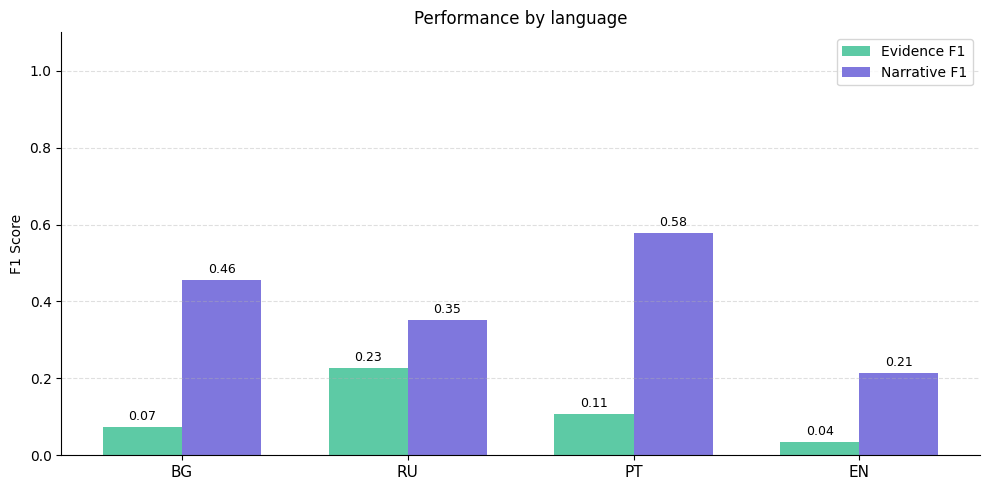

In [40]:
import matplotlib.pyplot as plt
import numpy as np

def plot_performance_by_language(results):
    
    by_lang = results["by_language"]
    languages = list(by_lang.keys())

    # extract metrics
    evidence_f1  = [by_lang[l].get("Evidence", {}).get("f1", 0) for l in languages]
    narrative_f1 = [by_lang[l].get("narrative", {}).get("f1", 0) for l in languages]

    x = np.arange(len(languages))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 5))

    bars1 = ax.bar(x - width/2, evidence_f1,  width, label="Evidence F1",  color="#5DCAA5")
    bars2 = ax.bar(x + width/2, narrative_f1, width, label="Narrative F1", color="#7F77DD")

    # value labels on bars
    for bar in bars1 + bars2:
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            h + 0.01,
            f"{h:.2f}",
            ha="center", va="bottom", fontsize=9
        )

    ax.set_xticks(x)
    ax.set_xticklabels(languages, fontsize=11)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel("F1 Score")
    ax.set_title("Performance by language")
    ax.legend()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()
    
plot_performance_by_language(test_results)

In [ ]:
import torch
import torch.nn as nn

bce_loss = nn.BCEWithLogitsLoss()
token_loss_fct = nn.CrossEntropyLoss(ignore_index=-100)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)

outputs = model(
    input_ids=batch["input_ids"],
    attention_mask=batch["attention_mask"]
)

# ----------------------
# Narrative loss
# ----------------------
narrative_loss = bce_loss(
    outputs["narrative_logits"],
    batch["narrative_labels"].float()
)

# ----------------------
# Token loss
# ----------------------
token_loss = token_loss_fct(
    outputs["token_logits"].view(-1, outputs["token_logits"].size(-1)),
    batch["token_labels"].view(-1)
)

# ----------------------
# Total loss (you control this now)
# ----------------------
loss = 0.5 * narrative_loss + 1.0 * token_loss

In [ ]:
from transformers import AutoModelForTokenClassification, TrainingArguments, Trainer

model = AutoModelForTokenClassification.from_pretrained(model_checkpoint, num_labels=len(label2id),

                                                        id2label=id2label, label2id=label2id)


In [ ]:



output_model_name = "my_model_stride_with_narrative_metric_stride"
args = TrainingArguments(
    output_model_name,
    report_to="none",
    eval_strategy = "epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16, #16
    per_device_eval_batch_size=16, #16
    num_train_epochs=100,
    weight_decay=0.01,
    save_strategy="epoch",
    load_best_model_at_end=True,      # Load the best model after training
    metric_for_best_model="eval_f1",       # Or any metric you use for evaluation
    greater_is_better=True,           # True if higher F1/Accuracy is better
    save_total_limit=1
    #push_to_hub=True,
)

In [ ]:
trainer = Trainer(
    model,
    args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics_stride
)

In [ ]:
#is cuda available?
import torch
print("CUDA available:", torch.cuda.is_available())


In [ ]:
trainer.train()

In [ ]:
trainer.save_model("my_model_stride_with_narrative_metric_stride")

In [ ]:
from transformers import AutoModelForTokenClassification, AutoTokenizer
#load model from "my_model_/checkpoint-epoch-xx"
model_path = "my_model_stride_with_narrative_metric_stride"
model = AutoModelForTokenClassification.from_pretrained(model_path)
tokenizer = AutoTokenizer.from_pretrained(model_path)

In [ ]:
trainer = Trainer(
    model,
    args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics_stride
)

In [ ]:
trainer.evaluate(test_dataset)

In [ ]:
from collections import defaultdict

from collections import defaultdict

def evaluate_with_tolerance_per_class(y_true_spans, y_pred_spans, tolerance=5):

    stats = defaultdict(lambda: {"tp": 0, "fp": 0, "fn": 0})

    for doc_true, doc_pred in zip(y_true_spans, y_pred_spans):
        matched_gold = set()

        # Count true positives and false positives
        for p_start, p_end, p_label in doc_pred:
            found_match = False
            for i, (g_start, g_end, g_label) in enumerate(doc_true):
                if i in matched_gold:
                    continue
                if g_label == p_label and abs(p_start - g_start) <= tolerance and abs(p_end - g_end) <= tolerance:
                    stats[p_label]["tp"] += 1
                    matched_gold.add(i)
                    found_match = True
                    break
            if not found_match:
                stats[p_label]["fp"] += 1

        # Count false negatives
        for i, (g_start, g_end, g_label) in enumerate(doc_true):
            if i not in matched_gold:
                stats[g_label]["fn"] += 1

    # Compute per-class precision, recall, F1
    results = {}
    total_tp, total_fp, total_fn = 0, 0, 0
    for label, s in stats.items():
        tp, fp, fn = s["tp"], s["fp"], s["fn"]
        precision = tp / (tp + fp) if tp + fp > 0 else 0
        recall = tp / (tp + fn) if tp + fn > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
        results[label] = {"precision": precision, "recall": recall, "f1": f1}
        total_tp += tp
        total_fp += fp
        total_fn += fn

    # Micro-averaged metrics
    micro_precision = total_tp / (total_tp + total_fp) if total_tp + total_fp > 0 else 0
    micro_recall = total_tp / (total_tp + total_fn) if total_tp + total_fn > 0 else 0
    micro_f1 = 2 * micro_precision * micro_recall / (micro_precision + micro_recall) if micro_precision + micro_recall > 0 else 0
    results["micro"] = {"precision": micro_precision, "recall": micro_recall, "f1": micro_f1}

    return results





def tokens_to_spans_2(pred_labels, offset_mapping):
    spans = []
    current_label = None
    start_char = None

    for (tok_start, tok_end), label in zip(offset_mapping, pred_labels):
        if label.startswith("B-"):
            if current_label is not None:
                spans.append((start_char, prev_end_char, current_label))
            current_label = label[2:]
            start_char = tok_start
        elif label.startswith("I-") and current_label == label[2:]:
            pass
        else:  # "O" or mismatched I-*
            if current_label is not None:
                spans.append((start_char, prev_end_char, current_label))
                current_label = None
        prev_end_char = tok_end

    if current_label is not None:
        spans.append((start_char, prev_end_char, current_label))

    return spans


def tokens_to_spans(pred_labels, offset_mapping):
    spans = []
    current_label = None
    start_char = None
    prev_end_char = None

    for (tok_start, tok_end), label in zip(offset_mapping, pred_labels):
        # Skip special tokens or padding
        if tok_start is None or tok_end is None or tok_start == tok_end:
            continue

        # Subword token: extend current span if inside one
        if label == -100:
            if current_label is not None:
                prev_end_char = tok_end
            continue

        if label.startswith("B-"):
            if current_label:
                spans.append((start_char, prev_end_char, current_label))
            current_label = label[2:]
            start_char = tok_start
        elif label.startswith("I-") and current_label == label[2:]:
            prev_end_char = tok_end
        else:  # O or mismatch
            if current_label:
                spans.append((start_char, prev_end_char, current_label))
                current_label = None

        prev_end_char = tok_end

    if current_label:
        spans.append((start_char, prev_end_char, current_label))

    return spans

def clean_labels_for_seqeval(labels):
    cleaned = []
    for doc_labels in labels:
        cleaned_doc = ["O" if l == -100 else l for l in doc_labels]
        cleaned.append(cleaned_doc)
    return cleaned

In [ ]:
from collections import defaultdict
import evaluate
metric = evaluate.load("seqeval")
from collections import defaultdict
import torch
import torch.nn.functional as F

def merge_stride_predictions_sequence(predictions, label_map):
    # Step 1: Collect entity spans per document
    doc_entities = defaultdict(list)  # doc_id -> list of (start_char, end_char, label, avg_conf)

    for sample in predictions:
        doc_id = sample["doc_id"]
        offsets = sample["offset_mapping"]
        logits_list = sample["logits"]
        labels = sample["labels"]

        # Convert token-level predictions to entity spans
        current_entity = None  # (start, end, label, sum_conf, token_count)
        for (start, end), logits, t in zip(offsets, logits_list, labels):
            if t == -100:
                continue  # skip subword/special tokens

            probs = F.softmax(torch.tensor(logits), dim=-1)
            best_conf, best_idx = torch.max(probs, dim=-1)
            pred_label = label_map[int(best_idx)]

            if pred_label.startswith("B-"):
                # save previous entity
                if current_entity is not None:
                    s, e, label, conf_sum, count = current_entity
                    avg_conf = conf_sum / count
                    doc_entities[doc_id].append((s, e, label, avg_conf))
                # start new entity
                current_entity = (start, end, pred_label[2:], best_conf.item(), 1)
            elif pred_label.startswith("I-") and current_entity is not None and pred_label[2:] == current_entity[2]:
                # extend current entity
                current_entity = (current_entity[0], end, current_entity[2], current_entity[3] + best_conf.item(), current_entity[4]+1)
            else:
                # O or mismatched I- tag: end current entity if any
                if current_entity is not None:
                    s, e, label, conf_sum, count = current_entity
                    avg_conf = conf_sum / count
                    doc_entities[doc_id].append((s, e, label, avg_conf))
                    current_entity = None
                # O tag is ignored for entity collection

        # flush last entity
        if current_entity is not None:
            s, e, label, conf_sum, count = current_entity
            avg_conf = conf_sum / count
            doc_entities[doc_id].append((s, e, label, avg_conf))
            current_entity = None

    # Step 2: Merge overlapping entities across windows
    merged_entities_per_doc = {}
    for doc_id, spans in doc_entities.items():
        if not spans:
            merged_entities_per_doc[doc_id] = []
            continue

        # Sort by start char
        spans = sorted(spans, key=lambda x: x[0])
        merged = [spans[0]]

        for span in spans[1:]:
            last = merged[-1]
            # If overlapping and same label, merge with longest/highest avg_conf
            if span[0] <= last[1] and span[2] == last[2]:
                new_start = min(last[0], span[0])
                new_end = max(last[1], span[1])
                new_avg_conf = max(last[3], span[3])  # pick higher avg confidence
                merged[-1] = (new_start, new_end, last[2], new_avg_conf)
            else:
                merged.append(span)

        merged_entities_per_doc[doc_id] = merged

    return merged_entities_per_doc



def merge_stride_predictions_confidence(predictions, label_map):

    doc_tokens = defaultdict(dict)  # doc_id -> {token_start: (best_conf, pred_label, true_label)}
    doc_offsets = defaultdict(list) # doc_id -> list of (start_char, end_char)
    for sample in predictions:
        doc_id = sample["doc_id"]
        offsets = sample["offset_mapping"]
        logits_list = sample["logits"]
        labels = sample["labels"]

        for (start, end), logits, t in zip(offsets, logits_list, labels):
            #if t == -100:
            #    continue  # skip subword/special tokens

            probs = F.softmax(torch.tensor(logits), dim=-1)
            best_conf, best_idx = torch.max(probs, dim=-1)
            pred_label = label_map[int(best_idx)]
            #true_label = label_map[int(t)]

            if t == -100:
                true_label = -100  # keep so subwords can extend span later
            else:
                true_label = label_map[int(t)]

            # if token already seen, keep the most confident prediction
            if start in doc_tokens[doc_id]:
                #if best_conf > doc_tokens[doc_id][start][0]:
                #    doc_tokens[doc_id][start] = (best_conf, pred_label, true_label)
                pass
            else:
                doc_tokens[doc_id][start] = (best_conf, pred_label, true_label)
            
            # keep track of document-level offsets
            if start not in [s for s, e in doc_offsets[doc_id]]:
                doc_offsets[doc_id].append((start, end))

    y_true_per_doc = []
    y_pred_per_doc = []

    for doc_id in doc_tokens:
        token_starts = sorted(doc_tokens[doc_id].keys())
        doc_true_labels = []
        doc_pred_labels = []

        for start in token_starts:
            _, pred_label, true_label = doc_tokens[doc_id][start]
            doc_pred_labels.append(pred_label)
            doc_true_labels.append(true_label)

        y_true_per_doc.append(doc_true_labels)
        y_pred_per_doc.append(doc_pred_labels)

        # sort offsets for the document
        doc_offsets[doc_id] = sorted(doc_offsets[doc_id], key=lambda x: x[0])
    return y_true_per_doc, y_pred_per_doc, doc_offsets



from seqeval.metrics import classification_report, f1_score
pred_spans_ner = []
gold_spans_ner = []
def compute_metrics_stride(eval_preds):
    global pred_spans_ner
    global gold_spans_ner
    logits, labels = eval_preds  # logits shape: (batch_size, seq_len, num_labels)
    
    predictions = []
    for i in range(len(logits)):
        predictions.append({
            "doc_id": test_dataset[i]["doc_id"],
            "offset_mapping": test_dataset[i]["offset_mapping"],
            "logits": logits[i],   # store raw logits, not argmax
            "labels": labels[i]
        })

    # merge overlapping chunk predictions using most confident token
    y_true, y_pred, doc_offsets  = merge_stride_predictions_confidence(predictions, model.config.id2label)
    print(len(y_true[0]), len(y_pred[0]), len(doc_offsets))
    all_pred_spans = []
    all_gold_spans = []
    #res = metric.compute(predictions=y_pred, references=clean_labels_for_seqeval(y_true))
    """return {
        "Claim_f1": res["Claim"]["f1"],
        "Claim_recall": res["Claim"]["recall"],
        "Claim_precision": res["Claim"]["precision"],
        "Non-claim_f1": res["Non-claim"]["f1"],
        "Non-claim_recall": res["Non-claim"]["recall"],
        "Non-claim_precision": res["Non-claim"]["precision"],
        "precision": res["overall_precision"],
        "recall": res["overall_recall"],
        "f1": res["overall_f1"],
        "accuracy": res["overall_accuracy"],
    }"""

    for i, doc_id in enumerate(doc_offsets.keys()):
        pred_spans = tokens_to_spans(y_pred[i], doc_offsets[doc_id])
        gold_spans = tokens_to_spans(y_true[i], doc_offsets[doc_id])
        all_pred_spans.append(pred_spans)
        all_gold_spans.append(gold_spans)
    pred_spans_ner = all_pred_spans
    gold_spans_ner = all_gold_spans

    results = evaluate_with_tolerance_per_class(all_gold_spans, all_pred_spans, tolerance=0)
        # Flatten nested dict so Trainer can find "eval_f1", "eval_precision", etc.
        
    flat = {}
    for label, scores in results.items():
        for metric_name, value in scores.items():
            flat[f"{label}_{metric_name}"] = value  # e.g. "Evidence_f1", "micro_f1"

    # Add top-level "f1" so Trainer's metric_for_best_model="eval_f1" works
    flat["f1"] = flat.get("micro_f1", 0.0)
    flat["precision"] = flat.get("micro_precision", 0.0)
    flat["recall"] = flat.get("micro_recall", 0.0)

    return flat


    

In [ ]:
trainer = Trainer(
    model,
    args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=data_collator,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics_stride
)

In [ ]:
trainer.evaluate()

In [ ]:
len(pred_spans_ner), len(gold_spans_ner)

In [ ]:
#read list of json files in ./nuno
import json
import os

def read_files(path):

    files_nuno = {}
    for file_names in os.listdir(path):
        if file_names.endswith('.json'):
            with open(os.path.join(path,file_names), 'rb') as f:
                data = json.load(f)
                files_nuno[file_names] = data
    return files_nuno

gemini_flash = read_files("./data/llm/gemini-2.5-flash")
gemini_flash_light = read_files("./data/llm/gemini-2.5-flash-lite")
gpt4o = read_files("./data/llm/gpt4o")

In [ ]:
len(gpt4o)

In [ ]:
test_file_names = [test_file["doc_id"] for test_file in test_files]
len(test_file_names)

In [ ]:


def get_annoations_gold(files, file_names):
    annotations = []
    for filename in file_names:
        for test_file in files:
                if test_file["doc_id"].split(".")[0] == filename.split(".")[0]:
                    tmp_test = []
                    for ann in test_file["evidence"]:
                        tmp_test.append((ann["begin"], ann["end"], "Evidence"))

                    if tmp_test == []:
                        print("No annotations found for", filename)
                    annotations.append(tmp_test)
    return annotations

def get_annotations(files, file_names):
     annotations = []
     for filename in file_names:
        for filename_nuno, file in files.items():
            if filename.split(".")[0] == filename_nuno.split(".")[0]:
                tmp_nuno = []
                for ann in file["extractions"]:
                    if ann["char_interval"]:
                        tmp_nuno.append((ann["char_interval"]["start_pos"], ann["char_interval"]["end_pos"], "Evidence"))
                annotations.append(tmp_nuno)
     return annotations
    #get data from test_files with the same filename and get the annotations to compare with nuno annotations



In [ ]:
gold_annotations = get_annoations_gold(test_files, test_file_names)


In [ ]:
gemini_flash_light_annotations = get_annotations(gemini_flash_light, test_file_names)
gemini_flash_annotations = get_annotations(gemini_flash, test_file_names)
gpt4o_annotations = get_annotations(gpt4o, test_file_names)
len(gpt4o_annotations), len(gold_annotations), len(gemini_flash_annotations), len(gemini_flash_light_annotations)

In [ ]:
def compute_claim_f1(pred_docs, gold_docs):
    print(len(pred_docs), len(gold_docs))
    assert len(pred_docs) == len(gold_docs), "Number of documents must match"

    labels = ["Evidence"]  # Only one label in this case
    counts = {label: {"tp": 0, "fp": 0, "fn": 0} for label in labels}

    for pred_spans, gold_spans in zip(pred_docs, gold_docs):
        pred_set = set(pred_spans)
        gold_set = set(gold_spans)

        for label in labels:
            #filter by label
            pred_label = {ann for ann in pred_set if ann[2] == label}
            gold_label = {ann for ann in gold_set if ann[2] == label}

            counts[label]["tp"] += len(pred_label & gold_label)
            counts[label]["fp"] += len(pred_label - gold_label)
            counts[label]["fn"] += len(gold_label - pred_label)

    results = {}
    total_tp = total_fp = total_fn = 0

    for label in labels:
        tp, fp, fn = counts[label]["tp"], counts[label]["fp"], counts[label]["fn"]
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        results[label] = {"precision": precision, "recall": recall, "f1": f1}
        total_tp += tp
        total_fp += fp
        total_fn += fn

    # Micro-average across both labels
    micro_p = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0.0
    micro_r = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0.0
    micro_f1 = 2 * micro_p * micro_r / (micro_p + micro_r) if (micro_p + micro_r) > 0 else 0.0

    results["micro_avg"] = {"precision": micro_p, "recall": micro_r, "f1": micro_f1}
    return results
compute_claim_f1(pred_spans_ner, gold_spans_ner)

In [ ]:
#print all models results
#print("GPT-4o Results:")
#compute_claim_f1(gpt4o_annotations, gold_annotations)
print("Gemini Flash Results:")
print(compute_claim_f1(gemini_flash_annotations, gold_annotations))
print("Gemini Flash Light Results:")
print(compute_claim_f1(gemini_flash_light_annotations, gold_annotations))
print("BERT Model Results:")
print(compute_claim_f1(pred_spans_ner, gold_annotations))

In [ ]:
ANN1: {'Claim': {'precision': 0.78,
  'recall': 0.8387096774193549,
  'f1': 0.8082901554404146},
 'Non-claim': {'precision': 0.9377245508982036,
  'recall': 0.8877551020408163,
  'f1': 0.9120559114735004},
 'micro_avg': {'precision': 0.9208556149732621,
  'recall': 0.8830769230769231,
  'f1': 0.9015706806282723}}


ANN2: {'Claim': {'precision': 0.7466666666666667,
  'recall': 0.6021505376344086,
  'f1': 0.6666666666666667},
 'Non-claim': {'precision': 0.9364754098360656,
  'recall': 0.518140589569161,
  'f1': 0.6671532846715329},
 'micro_avg': {'precision': 0.911190053285968,
  'recall': 0.5261538461538462,
  'f1': 0.6671001300390117}}




{'Claim': {'precision': 0.0005194805194805195,
  'recall': 0.010752688172043012,
  'f1': 0.0009910802775024777},
 'Non-claim': {'precision': 0.003244646333549643,
  'recall': 0.005668934240362812,
  'f1': 0.004127115146512588},
 'micro_avg': {'precision': 0.0017311021350259665,
  'recall': 0.006153846153846154,
  'f1': 0.002702094122945283}}

In [ ]:
gemini flash light
{'Claim': {'precision': 0.0, 'recall': 0.0, 'f1': 0.0},
 'Non-claim': {'precision': 0.004784688995215311,
  'recall': 0.003401360544217687,
  'f1': 0.003976143141153081},
 'micro_avg': {'precision': 0.0008818342151675485,
  'recall': 0.003076923076923077,
  'f1': 0.0013708019191226866}}

gemini-2.5:
{'Claim': {'precision': 0.0011723329425556857,
  'recall': 0.010752688172043012,
  'f1': 0.002114164904862579},
 'Non-claim': {'precision': 0.0016034206306787815,
  'recall': 0.003401360544217687,
  'f1': 0.002179440610243371},
 'micro_avg': {'precision': 0.0014684287812041115,
  'recall': 0.0041025641025641026,
  'f1': 0.0021627466882941336}}

gemini 2.5 flash lite
  {'Claim': {'precision': 0.0005194805194805195,
  'recall': 0.010752688172043012,
  'f1': 0.0009910802775024777},
 'Non-claim': {'precision': 0.003244646333549643,
  'recall': 0.005668934240362812,
  'f1': 0.004127115146512588},
 'micro_avg': {'precision': 0.0017311021350259665,
  'recall': 0.006153846153846154,
  'f1': 0.002702094122945283}}